# 03 — Risk Estimation

**Question:** which covariance estimator best forecasts *next month's* portfolio risk out of sample?

| Estimator | 1-week forecast |
|---|---|
| Sample | expanding-window sample covariance |
| Rolling | last 156 weeks (3 years) |
| EWMA | $\Sigma_t=\lambda\Sigma_{t-1}+(1-\lambda)r_{t-1}r_{t-1}^\top$, half-life 26 weeks ($\lambda\approx0.974$) |
| Ledoit-Wolf | $\delta F+(1-\delta)S$ on 156 weeks, $F$ = constant-correlation target |
| GARCH-CCC | $\sigma^2_{i,t}=\omega_i+\alpha_i r^2_{i,t-1}+\beta_i\sigma^2_{i,t-1}$ per asset (variance targeting, refit each January on the expanding window) + constant correlation of standardised residuals |

**Design.** Forecasts at every month-end from 2010-04-30 using only data up to that date; the forecast horizon is the number of weeks in the next month. Realised variance proxy = sum of squared weekly portfolio returns over that month (unbiased; QLIKE and MSE rankings remain consistent with a noisy proxy — Patton 2011).

**Hypotheses written before running the evaluation**

1. In crises (2020, 2022) EWMA and GARCH have clearly lower QLIKE than Sample.
2. Ledoit-Wolf gives the lowest realised volatility for the minimum-variance portfolio.
3. In calm periods the differences between estimators are not statistically significant.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import risk as K, evaluate as E, universe as U

pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 4)
PROC = ROOT / "data" / "processed"
weekly = pd.read_csv(PROC / "asset_returns_eur_weekly.csv", index_col=0, parse_dates=True)[U.ASSETS].dropna()
daily = pd.read_csv(PROC / "asset_returns_eur_daily.csv", index_col=0, parse_dates=True)[U.ASSETS]
monthly = pd.read_csv(PROC / "asset_returns_eur_monthly.csv", index_col=0, parse_dates=True)[U.ASSETS].dropna()
print(f"weekly: {weekly.index[0]:%Y-%m-%d} → {weekly.index[-1]:%Y-%m-%d}, {len(weekly)} weeks × {weekly.shape[1]} assets")

weekly: 2007-04-18 → 2026-09-30, 1016 weeks × 12 assets


## 1. Why weekly data — the Epps effect

All ETFs trade in New York and close together, but the synthetic EUR bond is priced off the ECB curve (Frankfurt) and the JGB off the MoF curve (Tokyo). Same-day returns of assets with different closing times reflect different news, so daily correlations are biased towards zero and part of the co-movement shows up one day later. Same-exchange pairs are the control group.

In [2]:
pairs = [("IEF", "JGB7_10_SYN", "NY–Tokyo"), ("IEF", "EUR_CORE7_10_SYN", "NY–Frankfurt"),
         ("EUR_CORE7_10_SYN", "JGB7_10_SYN", "Frankfurt–Tokyo"), ("SPY", "VGK", "NY–NY (control)"), ("TLT", "IEF", "NY–NY (control)")]
tbl = {}
for a, b, zone in pairs:
    dd = daily.loc["2007-05":, [a, b]].dropna()
    tbl[f"{a} – {b}"] = {"closes": zone, "daily": dd.corr().iloc[0, 1],
                         "next-day (a_t, b_t+1)": np.corrcoef(dd[a].iloc[:-1], dd[b].iloc[1:])[0, 1],
                         "weekly": weekly[[a, b]].corr().iloc[0, 1],
                         "monthly": monthly.loc["2007-05":, [a, b]].corr().iloc[0, 1]}
pd.DataFrame(tbl).T

,closes,daily,"next-day (a_t, b_t+1)",weekly,monthly
IEF – JGB7_10_SYN,NY–Tokyo,0.1238,0.3788,0.4631,0.5395
IEF – EUR_CORE7_10_SYN,NY–Frankfurt,0.4882,0.2411,0.6760,0.7445
EUR_CORE7_10_SYN – JGB7_10_SYN,Frankfurt–Tokyo,0.2306,0.2376,0.4985,0.5280
SPY – VGK,NY–NY (control),0.8357,-0.1424,0.7980,0.7620
TLT – IEF,NY–NY (control),0.9108,-0.0407,0.9068,0.9176


## 2. Walk-forward forecasts

197 forecast dates: 2010-04-30 → 2026-08-31


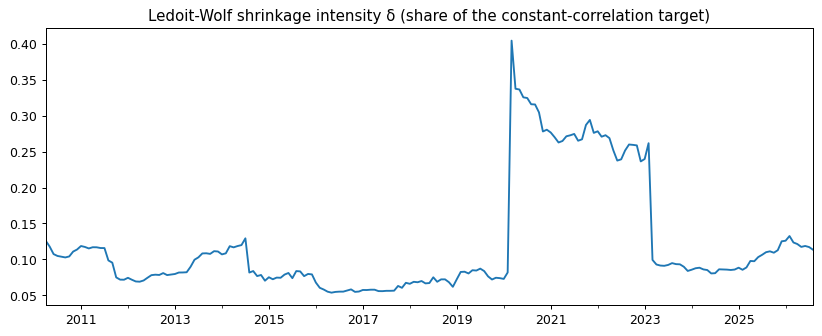

In [3]:
fc = K.walk_forward_forecasts(weekly)
K.save_forecasts(fc, PROC / "cov_forecasts.npz")
print(f"{len(fc['dates'])} forecast dates: {fc['dates'][0]:%Y-%m-%d} → {fc['dates'][-1]:%Y-%m-%d}")
delta = pd.Series(fc["lw_delta"], index=fc["dates"])
delta.plot(title="Ledoit-Wolf shrinkage intensity δ (share of the constant-correlation target)")
plt.show()

In [4]:
last_fit = list(fc["garch"])[-1]
pd.DataFrame({a: {"alpha": g.alpha, "beta": g.beta, "alpha+beta": g.persistence,
                  "long-run vol p.a.": np.sqrt(g.vbar * 52)} for a, g in zip(U.ASSETS, fc["garch"][last_fit])}).T.round(3)

,alpha,beta,alpha+beta,long-run vol p.a.
SPY,0.1320,0.7820,0.9140,0.1700
VGK,0.2400,0.6550,0.8950,0.1850
EWJ,0.1150,0.8150,0.9300,0.1800
SHY,0.1270,0.8670,0.9940,0.0140
IEF,0.0830,0.8940,0.9770,0.0660
TLT,0.1070,0.8270,0.9330,0.1420
EUR_CORE7_10_SYN,0.1340,0.8050,0.9390,0.0530
JGB7_10_SYN,0.0860,0.8940,0.9810,0.0270
LQD,0.1080,0.8260,0.9350,0.0840
HYG,0.1590,0.8200,0.9780,0.1020


GARCH fit on the expanding window up to the last January refit. Persistence α+β close to 1 means volatility shocks decay slowly; EWMA imposes exactly α+β = 1 and no long-run level.

## 3. Forecast accuracy on test portfolios

EW, the global 60/40 and 100 random long-only portfolios (Dirichlet weights, fixed seed).

In [5]:
ports = E.test_portfolios(U.ASSETS)
tab = E.variance_forecast_table(fc, weekly, ports)
tab["qlike"] = K.qlike(tab.realised, tab.forecast)
tab["sq_err"] = (tab.realised - tab.forecast) ** 2 * 1e6
tab["ratio"] = tab.realised / tab.forecast
summary = pd.DataFrame({
    "QLIKE EW": tab[tab.portfolio == "EW"].groupby("estimator").qlike.mean(),
    "QLIKE 60/40": tab[tab.portfolio == "60/40"].groupby("estimator").qlike.mean(),
    "QLIKE random (avg)": tab[tab.portfolio.str.startswith("rand")].groupby("estimator").qlike.mean(),
    "MSE ×1e6 random": tab[tab.portfolio.str.startswith("rand")].groupby("estimator").sq_err.mean(),
    "mean RV/forecast": tab.groupby("estimator").ratio.mean(),
    "median RV/forecast": tab.groupby("estimator").ratio.median(),
}).loc[K.ESTIMATORS]
summary.round(3)

,QLIKE EW,QLIKE 60/40,QLIKE random (avg),MSE ×1e6 random,mean RV/forecast,median RV/forecast
estimator,,,,,,
Sample,0.6370,0.5330,0.6090,0.9370,0.9520,0.5220
Rolling,0.8210,0.5870,0.7580,0.9580,1.2010,0.5860
EWMA,0.7600,0.5130,0.6970,0.9680,1.2240,0.6440
LedoitWolf,0.8190,0.5870,0.7560,0.9550,1.2020,0.5860
GARCH-CCC,0.5610,0.4310,0.5330,0.9160,1.1440,0.6920


**Diebold–Mariano test** against Sample (Newey–West, 3 lags). Negative statistic = lower loss than Sample.

In [6]:
rows = {}
for pf in ["EW", "60/40"]:
    q = tab[tab.portfolio == pf].pivot(index="date", columns="estimator", values="qlike")
    for e in K.ESTIMATORS[1:]:
        stat, p = K.diebold_mariano(q[e], q["Sample"])
        rows[(pf, e)] = {"DM stat": stat, "p-value": p, "QLIKE diff": (q[e] - q["Sample"]).mean()}
dm = pd.DataFrame(rows).T
dm.round(3)

DM stat  p-value  QLIKE diff
EW    Rolling      1.0480   0.2950      0.1840
      EWMA         0.9360   0.3490      0.1230
      LedoitWolf   1.0280   0.3040      0.1820
      GARCH-CCC   -2.2050   0.0270     -0.0750
60/40 Rolling      0.7410   0.4590      0.0540
      EWMA        -0.5970   0.5510     -0.0200
      LedoitWolf   0.7140   0.4750      0.0540
      GARCH-CCC   -2.4990   0.0120     -0.1020

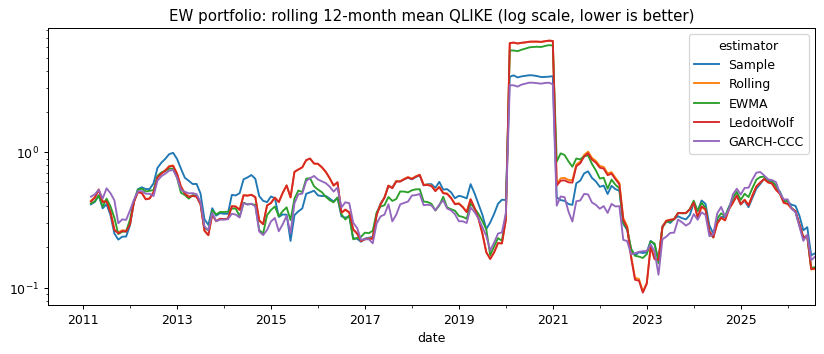

estimator,Sample,Rolling,EWMA,LedoitWolf,GARCH-CCC
COVID (forecasts 2020-01 … 2020-04),10.0060,18.7670,16.4210,18.8240,8.7470
Inflation shock (2021-12 … 2022-11),0.1830,0.1160,0.1700,0.1130,0.1840
Calm (all other months),0.4600,0.4710,0.4530,0.4670,0.4050


In [7]:
q_ew = tab[tab.portfolio == "EW"].pivot(index="date", columns="estimator", values="qlike")[K.ESTIMATORS]
q_ew.rolling(12).mean().plot(logy=True, title="EW portfolio: rolling 12-month mean QLIKE (log scale, lower is better)")
plt.show()
windows = {"COVID (forecasts 2020-01 … 2020-04)": ("2020-01-31", "2020-04-30"),
           "Inflation shock (2021-12 … 2022-11)": ("2021-12-31", "2022-11-30"),
           "Calm (all other months)": None}
crisis_idx = q_ew.loc["2020-01-31":"2020-04-30"].index.union(q_ew.loc["2021-12-31":"2022-11-30"].index)
by_window = {k: (q_ew.loc[v[0]:v[1]] if v else q_ew.drop(crisis_idx)).mean() for k, v in windows.items()}
pd.DataFrame(by_window).T.round(3)

In [8]:
calm = q_ew.drop(crisis_idx)
pd.DataFrame({e: dict(zip(["DM stat", "p-value"], K.diebold_mariano(calm[e], calm["Sample"]))) for e in K.ESTIMATORS[1:]}).T.round(3)

,DM stat,p-value
Rolling,0.4680,0.6400
EWMA,-0.2370,0.8130
LedoitWolf,0.3190,0.7500
GARCH-CCC,-2.1500,0.0320


## 4. Does a better forecast give a better minimum-variance portfolio?

Engle–Colacito style test: build the minimum-variance portfolio from each estimator at each month-end and measure its realised volatility over the next month.

In [9]:
mv = E.min_variance_oos(fc, weekly)
mv["vol"] = np.sqrt(mv.realised_var * 52 / mv.weeks)
mv.groupby(["type", "estimator"]).agg(**{"realised vol p.a.": ("vol", "mean"), "gross exposure": ("gross_exposure", "mean")}).unstack(0).round(4)

realised vol p.a.              gross exposure          
type       GMV unconstrained long-only GMV unconstrained long-only
estimator                                                         
EWMA                  0.0062    0.0092            1.6431    1.0000
GARCH-CCC             0.0061    0.0093            1.4240    1.0000
LedoitWolf            0.0070    0.0093            1.3223    1.0000
Rolling               0.0065    0.0094            1.6170    1.0000
Sample                0.0067    0.0096            1.4667    1.0000

## 5. Diagnostics

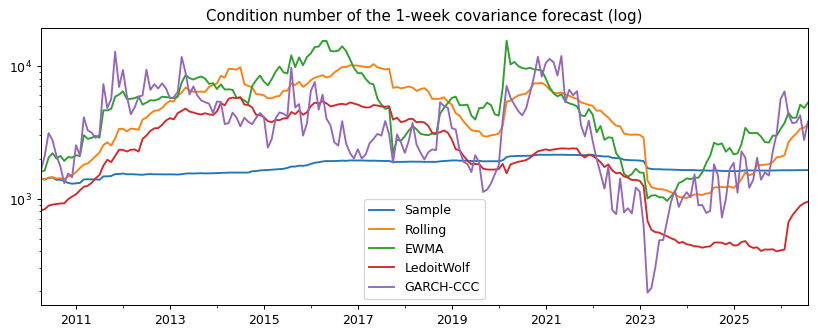

Sample       1661.0000
Rolling      4617.0000
EWMA         4947.0000
LedoitWolf   2260.0000
GARCH-CCC    3071.0000
Name: median condition number, dtype: float64

In [10]:
cond = pd.DataFrame({e: [np.linalg.cond(S) for S in fc["cov1w"][e]] for e in K.ESTIMATORS}, index=fc["dates"])
cond.plot(logy=True, title="Condition number of the 1-week covariance forecast (log)")
plt.show()
cond.median().round(0).rename("median condition number")

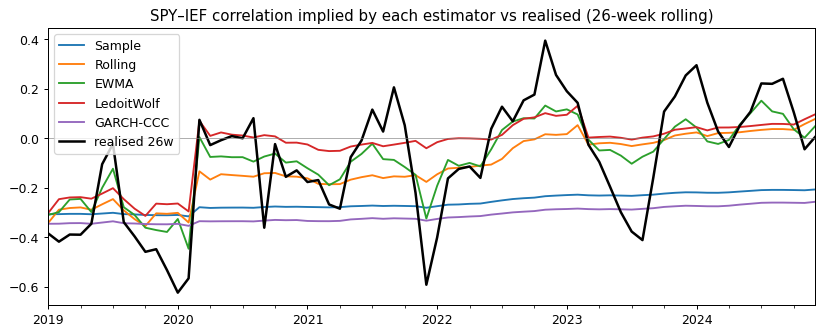

Sample            never
Rolling         2022-11
EWMA            2022-07
LedoitWolf      2022-03
GARCH-CCC         never
realised 26w    2021-07
Name: first month with positive SPY–IEF correlation after 2021-06, dtype: object

In [11]:
i, j = U.ASSETS.index("SPY"), U.ASSETS.index("IEF")
impl = pd.DataFrame({e: [S[i, j] / np.sqrt(S[i, i] * S[j, j]) for S in fc["cov1w"][e]] for e in K.ESTIMATORS}, index=fc["dates"])
real = weekly["SPY"].rolling(26).corr(weekly["IEF"]).resample("ME").last()
ax = impl.loc["2019":"2024"].plot(title="SPY–IEF correlation implied by each estimator vs realised (26-week rolling)")
real.loc["2019":"2024"].plot(ax=ax, color="k", lw=2, label="realised 26w"); ax.axhline(0, color="grey", lw=0.5); ax.legend(); plt.show()
first_pos = {e: impl.loc["2021-06":, e][impl.loc["2021-06":, e] > 0].index.min() for e in K.ESTIMATORS}
first_pos["realised 26w"] = real.loc["2021-06":][real.loc["2021-06":] > 0].index.min()
pd.Series({k: (v.strftime("%Y-%m") if pd.notna(v) else "never") for k, v in first_pos.items()}, name="first month with positive SPY–IEF correlation after 2021-06")

## Hypotheses — verdict

| # | Hypothesis | Verdict |
|---|---|---|
| 1 | EWMA and GARCH beat Sample in crises | **Partly rejected.** In COVID GARCH-CCC was best (QLIKE 8.7 vs Sample 10.0) but EWMA was among the worst (16.4): after a calm 2019 its short memory under-forecast the shock, while Sample still remembered 2008. In 2022 the 3-year estimators (Rolling, Ledoit-Wolf) won. |
| 2 | Ledoit-Wolf gives the lowest min-variance volatility | **Rejected.** Long-only min-variance volatility is 0.92–0.96% p.a. for every estimator — the long-only constraint and the very low-volatility hedged short bonds dominate. Unconstrained, GARCH-CCC is lowest (0.61%) and LW highest (0.70%). |
| 3 | No significant differences in calm periods | **Rejected for GARCH-CCC only.** Excluding the crisis windows GARCH-CCC still beats Sample (DM p = 0.03); Rolling, EWMA and LW do not. |

## Takeaways

* **GARCH-CCC is the only estimator that beats Sample significantly** — overall (DM p = 0.03 EW, 0.01 60/40) and in calm periods. Mean reversion to a long-run level matters: EWMA has the speed but no anchor.
* **All forecasts are too high in normal months and too low in shocks** (median RV/forecast 0.5–0.7, mean ≈ 1–1.2). Notebook 06 must judge VaR with this asymmetry in mind.
* **Correlation dynamics are the blind spot of CCC.** The SPY–IEF correlation turned positive in realised data in 2021-07; Ledoit-Wolf picked it up in 2022-03, EWMA 2022-07, Rolling 2022-11 — GARCH-CCC and Sample never did, by construction. DCC-GARCH (v1.x) targets exactly this.
* **Ledoit-Wolf halves the condition number of the 3-year sample** (≈2.3k vs 4.6k) with δ ≈ 0.06–0.28 — its value is numerical stability for optimisers, not forecast accuracy.
* **Weekly estimation is justified** for the cross-time-zone bonds (IEF–JGB daily 0.12 vs weekly 0.46) and costs nothing for same-exchange pairs.

**Choice for notebook 04:** GARCH-CCC as the primary covariance input. Notebook 05 re-runs the backtest with every estimator, since a better variance forecast did not translate into a materially better long-only min-variance portfolio.